# NN_L13_coverage

**Empirical coverage of 50, 80 and 90 percent intervals for Romanian day-ahead prices in the test year: raw Chronos-2 quantiles, the same after a rolling split-conformal correction (60 days), and LEAR with empirical errors.**

Neural Networks and Deep Learning (NN), Lecture 13 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L13/NN_L13_coverage/NN_L13_coverage.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

raw coverage 50 % = 45.6   [cov.chronos2.50.cov]
conformal coverage 50 % = 49.5   [cov.chronos2_conf.50.cov]


raw coverage 80 % = 76.5   [cov.chronos2.80.cov]
conformal coverage 80 % = 79.3   [cov.chronos2_conf.80.cov]


raw coverage 90 % = 88.3   [cov.chronos2.90.cov]
conformal coverage 90 % = 89.4   [cov.chronos2_conf.90.cov]


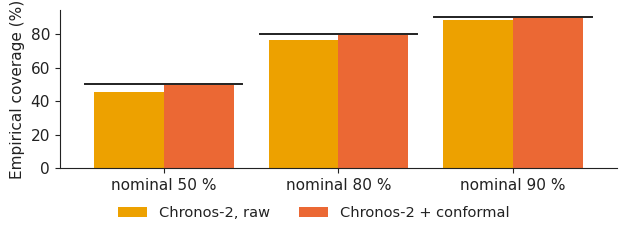

In [3]:
RES = REPO + 'lectures/L13/results/'
Q = pd.read_csv(RES + 'quantiles_hourly.csv', parse_dates=['date'])
test = Q[(Q.date >= '2025-11-01') & (Q.date <= '2026-10-31')]
def wide(col):
    return Q.pivot(index='date', columns='hour', values=col)
Y = wide('actual')
days = [d for d in sorted(test.date.unique()) if Y.loc[d].notna().all()]
def conformal(lo_c, hi_c, alpha, cal=60):
    lo, hi = wide(lo_c), wide(hi_c)
    s = np.maximum(lo - Y, Y - hi)
    out_lo, out_hi = [], []
    for D in days:
        w = s.loc[D - pd.Timedelta(days=cal):D - pd.Timedelta(days=1)].values.ravel()
        w = w[~np.isnan(w)]
        n = len(w)
        q = np.quantile(w, min(1.0, np.ceil((n + 1) * (1 - alpha)) / n))
        out_lo.append(lo.loc[D].values - q)
        out_hi.append(hi.loc[D].values + q)
    return np.array(out_lo), np.array(out_hi)
y = Y.loc[days].values
def cov(lo, hi):
    return round(100 * float(((y >= lo) & (y <= hi)).mean()), 1)
levels = {'50': ('ch2_q25', 'ch2_q75', 0.5), '80': ('ch2_q10', 'ch2_q90', 0.2), '90': ('ch2_q05', 'ch2_q95', 0.1)}
raw, con = {}, {}
for k, (a, b, al) in levels.items():
    raw[k] = cov(wide(a).loc[days].values, wide(b).loc[days].values)
    con[k] = cov(*conformal(a, b, al))
    show(f'cov.chronos2.{k}.cov', f'raw coverage {k} %', raw[k])
    show(f'cov.chronos2_conf.{k}.cov', f'conformal coverage {k} %', con[k])
fig, ax = plt.subplots(figsize=(6.4, 2.4))
ks = ['50', '80', '90']
ax.bar(np.arange(3) - 0.2, [raw[k] for k in ks], 0.4, color=PAL['alt'], label='Chronos-2, raw')
ax.bar(np.arange(3) + 0.2, [con[k] for k in ks], 0.4, color=PAL['model'], label='Chronos-2 + conformal')
for j, k in enumerate(ks):
    ax.plot([j - 0.45, j + 0.45], [int(k)] * 2, color='#222222')
ax.set_xticks(range(3))
ax.set_xticklabels([f'nominal {k} %' for k in ks])
ax.set_ylabel('Empirical coverage (%)')
legend_bottom(fig)
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig('coverage.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()